In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

In [2]:
def generate_degrees(n, distribution="powerlaw", gamma=1.5, mean=4):
    values = np.arange(1, n)

    while True:
        if distribution == "powerlaw":
            probabilities = values.astype(float) ** (-gamma)
            probabilities /= probabilities.sum()
            d = rng.choice(values, size=n, p=probabilities)

        elif distribution == "poisson":
            d = np.clip(rng.poisson(mean, size=n), 0, n - 1)

        elif distribution == "uniform":
            d = rng.integers(0, n, size=n)

        else:
            raise ValueError("Unknown distribution")

        if d.sum() % 2 == 0:
            return np.sort(d)[::-1]


def erdos_gallai_deficit(d):
    d = np.sort(np.asarray(d, dtype=np.int64))[::-1]
    n = len(d)

    delta = np.zeros(n, dtype=np.int64)

    for k in range(1, n + 1):
        S = d[:k].sum()
        R = k * (k - 1) + np.minimum(k, d[k:]).sum()
        delta[k - 1] = R - S

    return delta

def find_last_negative_index(d):
    last_negative_index = next((i for i in range(len(d) - 1, -1, -1) if d[i] < 0), -1)
    return last_negative_index + 1

def k_star_index(d):
    return int(np.argmin(d) + 1)

def eg_summary(d):
    delta = erdos_gallai_deficit(d)
    violations = np.where(delta < 0)[0]

    graphical = (sum(d) % 2 == 0) and (len(violations) == 0)

    if len(violations) == 0:
        return {"graphical": graphical, "k_first": None,
                "k_star": None, "F": 0}

    return {
        "graphical": False,
        "k_first": int(violations[0] + 1),
        "k_star": int(np.argmin(delta) + 1),
        "F": int(-delta.min())
    }


def plot_eg(d, label=None):
    delta = erdos_gallai_deficit(d)
    k = np.arange(1, len(d) + 1)
    summary = eg_summary(d)

    plt.figure(figsize=(9, 4))
    plt.plot(k, delta, label=label or "EG slack")
    plt.axhline(0, color="black", linestyle="--", linewidth=1)

    if summary["k_first"] is not None:
        first = summary["k_first"]
        worst = summary["k_star"]

        plt.scatter(first, delta[first - 1], color="orange",
                    zorder=3, label=f"First violation: k={first}")
        plt.scatter(worst, delta[worst - 1], color="red",
                    zorder=3, label=f"Largest violation: k={worst}")

    plt.xlabel("k")
    plt.ylabel(r"$\Delta_k = R_k - S_k$")
    plt.title(f"Erdős–Gallai profile — graphical: {summary['graphical']}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


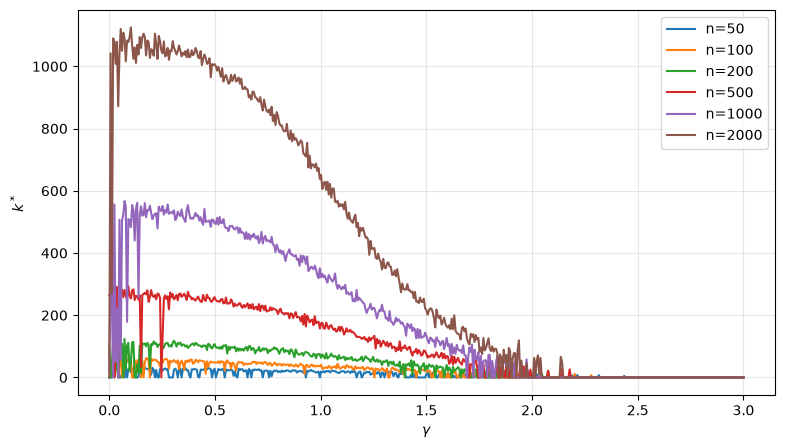

In [3]:
gammas = np.linspace(0, 3.0, 501)

plt.figure(figsize=(9, 5))


for n in [50 ,100, 200, 500, 1000, 2000]:
    k_star = []
    for gamma in gammas:
        d = generate_degrees(n, "powerlaw", gamma=gamma)
        delta = erdos_gallai_deficit(d)
        k_star.append(find_last_negative_index(delta))

    plt.plot(gammas, k_star, label=f"n={n}")
    
plt.xlabel(r"$\gamma$")
plt.ylabel(r"$k^*$")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


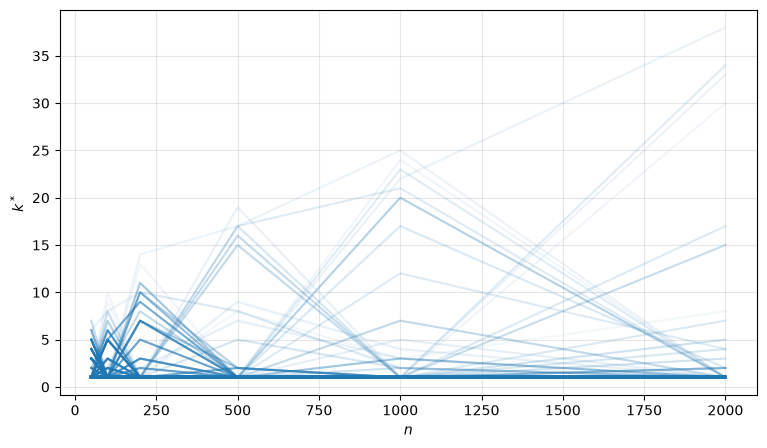

In [78]:
gammas = np.linspace(2, 3, 301)
ns = [50, 100, 200, 500, 1000, 2000]

plt.figure(figsize=(9, 5))

for gamma in gammas:
    k_star = []
    for n in ns:
        d = generate_degrees(n, "powerlaw", gamma=gamma)
        delta = erdos_gallai_deficit(d)
        k_star.append(k_star_index(delta))

    alpha = 0.05 + 0.9 * (gamma - gammas.min()) / (gammas.max() - gammas.min())
    plt.plot(ns, k_star, color="tab:blue", alpha=alpha)

plt.xlabel(r"$n$")
plt.ylabel(r"$k^*$")
plt.grid(alpha=0.3)
plt.show()

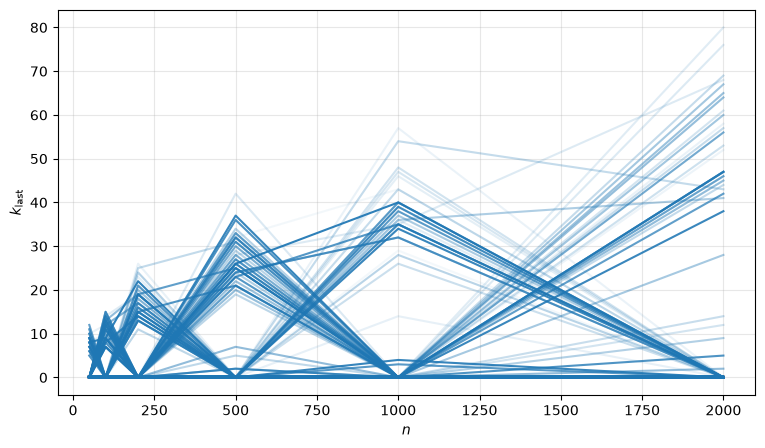

In [72]:
gammas = np.linspace(2, 2.1, 301)
ns = [50, 100, 200, 500, 1000, 2000]

plt.figure(figsize=(9, 5))

for gamma in gammas:
    k_last = []
    for n in ns:
        d = generate_degrees(n, "powerlaw", gamma=gamma)
        delta = erdos_gallai_deficit(d)
        k_last.append(find_last_negative_index(delta))

    alpha = 0.05 + 0.9 * (gamma - gammas.min()) / (gammas.max() - gammas.min())
    plt.plot(ns, k_last, color="tab:blue", alpha=alpha)

plt.xlabel(r"$n$")
plt.ylabel(r"$k_{\text{last}}$")
plt.grid(alpha=0.3)
plt.show()

In [61]:
def Q(d):
    """Minimum total L1 degree discrepancy, for an even-sum target."""
    delta = erdos_gallai_deficit(d)
    F = max(0, -int(delta.min()))
    return 2 * ((F + 1) // 2)

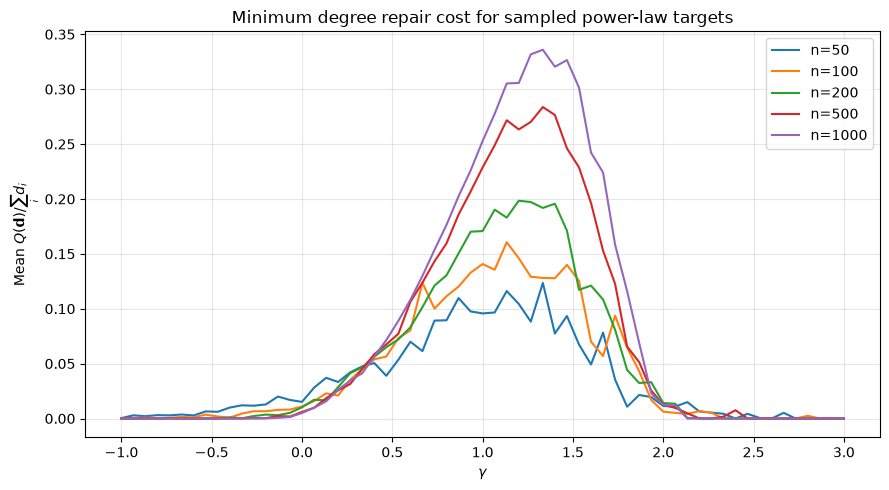

In [6]:
gammas = np.linspace(-1, 3, 61)
sizes = [50, 100, 200, 500, 1000]
repeats = 30

normalised = True

rng = np.random.default_rng(42)

fig, ax = plt.subplots(figsize=(9, 5))

for n in sizes:
    mean_values = []

    for gamma in gammas:
        values = []

        for _ in range(repeats):
            d = generate_degrees(n, "powerlaw", gamma=gamma)
            q = Q(d)

            values.append(q / d.sum() if normalised else q)

        mean_values.append(np.mean(values))

    ax.plot(gammas, mean_values, label=f"n={n}")

ax.set_xlabel(r"$\gamma$")
ax.set_ylabel(r"Mean $Q(\mathbf{d})/\sum_i d_i$" if normalised else r"Mean $Q(\mathbf{d})$")
ax.set_title("Minimum degree repair cost for sampled power-law targets")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Failed 5000/5000 sequences for n=1000, gamma=1.5


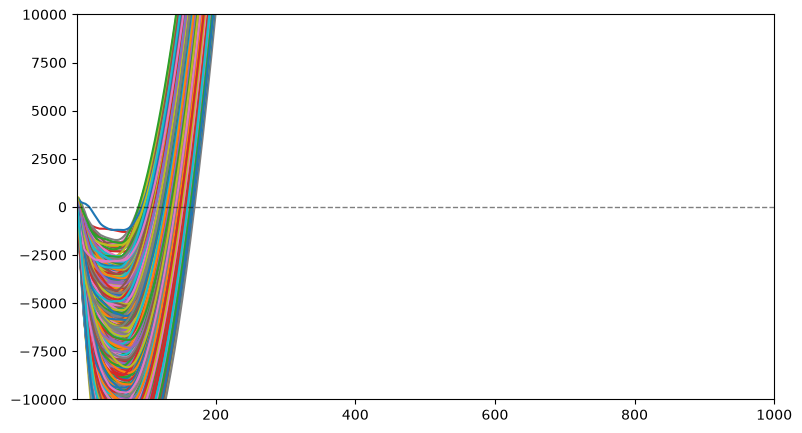

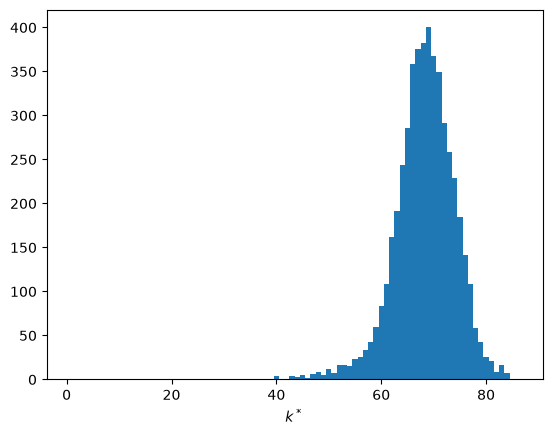

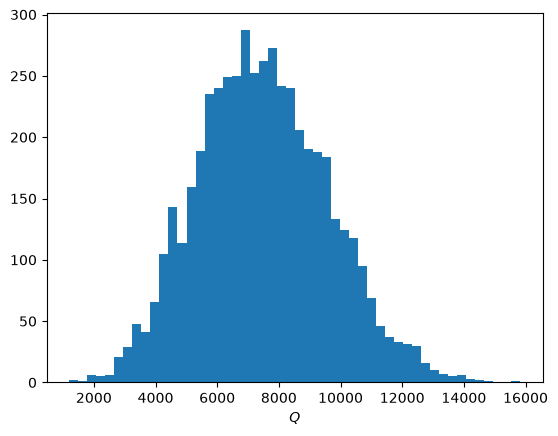

In [63]:
N = 5000
seq_len = 1000
gamma = 1.5

failed = 0
k_star = []
Qs = []

plt.figure(figsize=(9, 5))
for i in range(N):
    d = generate_degrees(seq_len, "powerlaw", gamma=gamma)
    deficit = erdos_gallai_deficit(d)
    if any(deficit < 0):
        failed += 1
        k_star.append(k_star_index(deficit))
        Qs.append(Q(d))


    plt.plot(np.arange(1, len(d) + 1), deficit)


plt.xlim(1,1000)
plt.ylim(-10000, 10000)
plt.axhline(0, color="black", linestyle="--", linewidth=1, alpha=0.5)
print(f"Failed {failed}/{N} sequences for n={seq_len}, gamma={gamma}")
plt.show()

plt.hist(k_star, bins=np.arange(1, max(k_star) + 2) - 0.5, density=False)
plt.xlabel(r"$k^*$")
plt.show()

plt.hist(Qs, bins=50, density=False)
plt.xlabel(r"$Q$")
plt.show()